In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split 
from joblib import dump, load
from tensorflow.keras.models import Model 
from tensorflow.keras.layers import Input, Dense
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

C:\ProgramData\anaconda3\envs\ids_env\lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
COLUMNS = ['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 
           'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dnpkt', 'sjit', 'djit', 
           'swin', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 
           'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 
           'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 
           'is_sm_ips_ports', 'attack_cat', 'label']

file_list = ['UNSW-NB15_1.csv', 'UNSW-NB15_2.csv', 'UNSW-NB15_3.csv', 'UNSW-NB15_4.csv']
list_of_dfs = []

print("Start Merging Files")



try:
    for filename in file_list:
        df = pd.read_csv(filename, header=None, names=COLUMNS)
        list_of_dfs.append(df)
    
    combined_df = pd.concat(list_of_dfs, ignore_index=True)
    print(f"Merge all files successfully and the size is : {combined_df.shape}")
except FileNotFoundError:
    print(f" I can't find some file : {file_list}")
    raise

Start Merging Files
Merge all files successfully and the size is : (2540047, 43)


In [3]:
def preprocess_data(df):
    
    df.replace(['-', ' ', np.inf, -np.inf], np.nan, inplace=True) 
    df.drop(['id'], axis=1, inplace=True, errors='ignore') 

    categorical_features = ['proto', 'service', 'state']
    for col in categorical_features:
        if col in df.columns:
            df[col] = df[col].astype(str).astype('category').cat.codes
        
    feature_cols_temp = [col for col in df.columns if col not in ['label', 'attack_cat']]

    cols_to_keep = []
    for col in feature_cols_temp:
        df[col] = pd.to_numeric(df[col], errors='coerce') 
        if df[col].isna().all():
            print(f"   Warning the '{col}' Deleted completly because it was empty")
            df.drop(col, axis=1, inplace=True)
        else:
            cols_to_keep.append(col)    
    feature_cols_final = cols_to_keep
    df.dropna(subset=feature_cols_final, inplace=True)
    return df, feature_cols_final
    
combined_df_cleaned, feature_cols = preprocess_data(combined_df.copy())
print(f"The Size of Data after Cleanning: {combined_df_cleaned.shape}")


   Warning the 'sbytes' Deleted completly because it was empty
The Size of Data after Cleanning: (1087203, 41)


In [4]:
TEST_SIZE_RATIO = 0.3
SEED = 42
df_train_cleaned, df_test_cleaned = train_test_split(
    combined_df_cleaned, 
    test_size=TEST_SIZE_RATIO, 
    random_state=SEED, 
    shuffle=True,
    stratify=combined_df_cleaned['label'] 
)

print(f"The data has been split")
print(f"Size of Train Set (df_train_cleaned): {df_train_cleaned.shape}")
print(f"Size of Test Set (df_test_cleaned): {df_test_cleaned.shape}")

The data has been split
Size of Train Set (df_train_cleaned): (761042, 41)
Size of Test Set (df_test_cleaned): (326161, 41)


In [5]:
scaler = MinMaxScaler()

X_train_features = scaler.fit_transform(df_train_cleaned[feature_cols])
X_test_features = scaler.transform(df_test_cleaned[feature_cols])
X_train_df = pd.DataFrame(X_train_features, columns=feature_cols)
X_test_df = pd.DataFrame(X_test_features, columns=feature_cols)

dump(scaler, 'scaler_unsw_nb15.joblib')
print(" Saving MinMaxScaler Object gone just right")
train_labels = df_train_cleaned['label'].reset_index(drop=True)
X_train_ae = X_train_df[train_labels == 0].reset_index(drop=True) 

if X_train_ae.shape[0] > 1:
    X_train_ae, X_test_ae_val = train_test_split(X_train_ae, test_size=0.2, random_state=42)
else:
    X_test_ae_val = pd.DataFrame() 
    print("The number of natural samples are small for splliting")

y_train_cat_original = df_train_cleaned['attack_cat'].reset_index(drop=True)
y_test_cat_original = df_test_cleaned['attack_cat'].reset_index(drop=True)

print(f"Size of Autoencoder Train Data Set is: {X_train_ae.shape}")
print(f"Size of overall Train Data Set is: {X_train_df.shape}")
print(f"Size of overall Test Data Set is: {X_test_df.shape}")

 Saving MinMaxScaler Object gone just right
Size of Autoencoder Train Data Set is: (596393, 39)
Size of overall Train Data Set is: (761042, 39)
Size of overall Test Data Set is: (326161, 39)


In [6]:
print("Start Trainning Autoencoder")

input_dim = X_train_ae.shape[1] 

input_layer = Input(shape=(input_dim,))
encoder = Dense(128, activation='relu')(input_layer)
encoder = Dense(64, activation='relu')(encoder)
bottleneck = Dense(32, activation='relu')(encoder) # Bottel Neck
decoder = Dense(64, activation='relu')(bottleneck)
decoder = Dense(128, activation='relu')(decoder)
decoder_output = Dense(input_dim, activation='sigmoid')(decoder)

autoencoder = Model(inputs=input_layer, outputs=decoder_output)
autoencoder.compile(optimizer='adam', loss='mean_squared_error')

history_ae = autoencoder.fit(X_train_ae, X_train_ae,
                              epochs=50, 
                              batch_size=512,
                              shuffle=True,
                              validation_data=(X_test_ae_val, X_test_ae_val),
                              verbose=0) 

autoencoder.save('autoencoder_model.keras')
predictions_ae = autoencoder.predict(X_test_ae_val, verbose=0)
mse_ae = np.mean(np.power(X_test_ae_val - predictions_ae, 2), axis=1)
THRESHOLD = np.quantile(mse_ae, 0.95) 

print("Autoencoder Results")
print(f"Threshold is (THRESHOLD) Based on rebuild error : {THRESHOLD:.6f}")
print("Autoencoder Saved")

Start Trainning Autoencoder
Autoencoder Results
Threshold is (THRESHOLD) Based on rebuild error : 0.000037
Autoencoder Saved


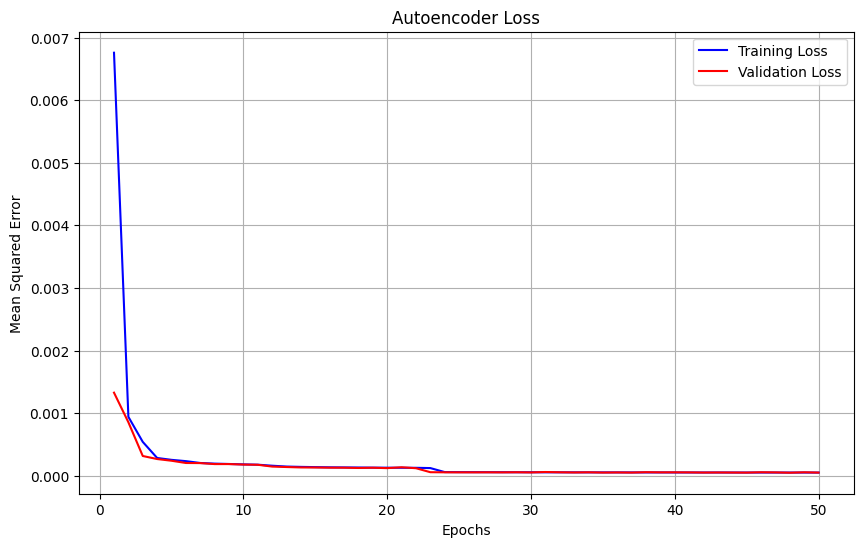

In [7]:
if 'history_ae' in locals():
    
    loss = history_ae.history['loss']
    val_loss = history_ae.history['val_loss']
    epochs = range(1, len(loss) + 1)
    
    plt.figure(figsize=(10, 6))
    plt.plot(epochs, loss, 'b', label='Training Loss')
    plt.plot(epochs, val_loss, 'r', label='Validation Loss')
    plt.title('Autoencoder Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Mean Squared Error')
    plt.legend()
    plt.grid(True)
    plt.show()

else:
    print("Some Error")

In [8]:
from tensorflow.keras.models import load_model
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
try:
    autoencoder = load_model('autoencoder_model.keras')
except:
    autoencoder = load_model('autoencoder_model.h5')

predictions_train = autoencoder.predict(X_train_df, verbose=0)
mse_train = np.mean(np.power(X_train_df - predictions_train, 2), axis=1)

predictions_test = autoencoder.predict(X_test_df, verbose=0)
mse_test = np.mean(np.power(X_test_df - predictions_test, 2), axis=1)

is_attack_train = (mse_train > THRESHOLD).astype(int)
is_attack_test = (mse_test > THRESHOLD).astype(int)

X_classifier_train = X_train_df[is_attack_train == 1].reset_index(drop=True)
y_classifier_train_cat = y_train_cat_original[is_attack_train == 1].reset_index(drop=True)

X_classifier_test = X_test_df[is_attack_test == 1].reset_index(drop=True)
y_classifier_test_cat = y_test_cat_original[is_attack_test == 1].reset_index(drop=True)

y_classifier_train_cat = y_classifier_train_cat[y_classifier_train_cat != 'Normal']
y_classifier_test_cat = y_classifier_test_cat[y_classifier_test_cat != 'Normal']

X_classifier_train = X_classifier_train.iloc[y_classifier_train_cat.index]
X_classifier_test = X_classifier_test.iloc[y_classifier_test_cat.index]

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_classifier_train_cat)
y_test_encoded = label_encoder.transform(y_classifier_test_cat)

y_train_one_hot = to_categorical(y_train_encoded)
y_test_one_hot = to_categorical(y_test_encoded)

dump(label_encoder, 'label_encoder_attacks.joblib')

print(f"Summarize the classifier data")
print(f"Classifier training data size : {X_classifier_train.shape}")
print(f" Number of attack categories coded: {len(label_encoder.classes_)}")
print(f"   Kinds of discover attacks : {label_encoder.classes_}")

Summarize the classifier data
Classifier training data size : (52130, 39)
 Number of attack categories coded: 10
   Kinds of discover attacks : [' Fuzzers' 'Analysis' 'Backdoors' 'DoS' 'Exploits' 'Generic'
 'Reconnaissance' 'Shellcode' 'Worms' nan]


In [9]:
from tensorflow.keras.layers import Conv1D, MaxPooling1D, LSTM, Flatten
print("Starting CNN + LSTM")

N_FEATURES = X_classifier_train.shape[1]

X_train_cl_3d = X_classifier_train.values.reshape(X_classifier_train.shape[0], N_FEATURES, 1)
X_test_cl_3d = X_classifier_test.values.reshape(X_classifier_test.shape[0], N_FEATURES, 1)

num_classes = y_train_one_hot.shape[1]
input_shape = (N_FEATURES, 1)
input_cl = Input(shape=input_shape)

conv = Conv1D(filters=64, kernel_size=3, activation='relu')(input_cl)
conv = Conv1D(filters=32, kernel_size=3, activation='relu')(conv)
lstm = LSTM(32, return_sequences=False)(conv)

# Dense Output
dense = Dense(64, activation='relu')(lstm)
output_cl = Dense(num_classes, activation='softmax')(dense)

hybrid_classifier = Model(inputs=input_cl, outputs=output_cl)
hybrid_classifier.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history_cl = hybrid_classifier.fit(
    X_train_cl_3d, y_train_one_hot,
    epochs=25, 
    batch_size=512,
    validation_data=(X_test_cl_3d, y_test_one_hot),
    verbose=1)

hybrid_classifier.save('hybrid_classifier_model.keras')
print("Trainning and Saving CNN + LSTM")

Starting CNN + LSTM
Epoch 1/25
102/102 ━━━━━━━━━━━━━━━━━━━━ 11s 83ms/step - accuracy: 0.7000 - loss: 1.3476 - val_accuracy: 0.7133 - val_loss: 1.0590
Epoch 2/25
102/102 ━━━━━━━━━━━━━━━━━━━━ 8s 75ms/step - accuracy: 0.7330 - loss: 0.9198 - val_accuracy: 0.7857 - val_loss: 0.6938
Epoch 3/25
102/102 ━━━━━━━━━━━━━━━━━━━━ 8s 78ms/step - accuracy: 0.7942 - loss: 0.6360 - val_accuracy: 0.7994 - val_loss: 0.5947
Epoch 4/25
102/102 ━━━━━━━━━━━━━━━━━━━━ 8s 79ms/step - accuracy: 0.8037 - loss: 0.5687 - val_accuracy: 0.8152 - val_loss: 0.5262
Epoch 5/25
102/102 ━━━━━━━━━━━━━━━━━━━━ 8s 81ms/step - accuracy: 0.8412 - loss: 0.4783 - val_accuracy: 0.8453 - val_loss: 0.4671
Epoch 6/25
102/102 ━━━━━━━━━━━━━━━━━━━━ 8s 79ms/step - accuracy: 0.8583 - loss: 0.4177 - val_accuracy: 0.8580 - val_loss: 0.3940
Epoch 7/25
102/102 ━━━━━━━━━━━━━━━━━━━━ 9s 83ms/step - accuracy: 0.8677 - loss: 0.3739 - val_accuracy: 0.8581 - val_loss: 0.4007
Epoch 8/25
102/102 ━━━━━━━━━━━━━━━━━━━━ 8s 78ms/step - accuracy: 0.8708 - lo

In [ ]:
from sklearn.metrics import classification_report, accuracy_score
print("Starting our Hybrid model")

try:
    autoencoder_model = load_model('autoencoder_model.keras')
except:
    autoencoder_model = load_model('autoencoder_model.h5') 
try:
    hybrid_classifier = load_model('hybrid_classifier_model.keras')
except:
    hybrid_classifier = load_model('hybrid_classifier_model.h5') 

le_object = load('label_encoder_attacks.joblib')

def classify_cascaded(sample_scaled_df, ae_model, hybrid_model, le_object, threshold):
    sample_scaled = sample_scaled_df.values.reshape(1, -1)
    
    reconstruction_prediction = ae_model.predict(sample_scaled, verbose=0)
    mse = np.mean(np.power(sample_scaled - reconstruction_prediction, 2), axis=1)[0]
    
    if mse < threshold:
        return "Normal"
    else:
        N_FEATURES = sample_scaled.shape[1]
        sample_3d = sample_scaled.reshape(1, N_FEATURES, 1) 
        attack_prediction_prob = hybrid_model.predict(sample_3d, verbose=0)
        predicted_index = np.argmax(attack_prediction_prob, axis=1)[0]
        attack_name = le_object.inverse_transform([predicted_index])[0]
        return attack_name

N_SAMPLES = len(X_test_df)
X_test_sample = X_test_df.head(N_SAMPLES)
y_test_labels_cat = df_test_cleaned['attack_cat'].head(N_SAMPLES).reset_index(drop=True)

y_pred_cascaded = []
for index, row in X_test_sample.iterrows():
    numeric_df_row = row.to_frame().T.astype(np.float64) 
    prediction = classify_cascaded(numeric_df_row, autoencoder_model, hybrid_classifier, le_object, THRESHOLD)
    y_pred_cascaded.append(prediction)

y_pred_series = pd.Series(y_pred_cascaded, name='Predicted')

y_true_final = y_test_labels_cat.astype(str)
y_pred_final = y_pred_series.astype(str)

print("Final Performance Report for the Series Hybrid System")
print(classification_report(y_true_final, y_pred_final, zero_division=0))
print(f"Total accurency of our system {accuracy_score(y_true_final, y_pred_final)*100:.2f}%")

Starting our Hybrid model


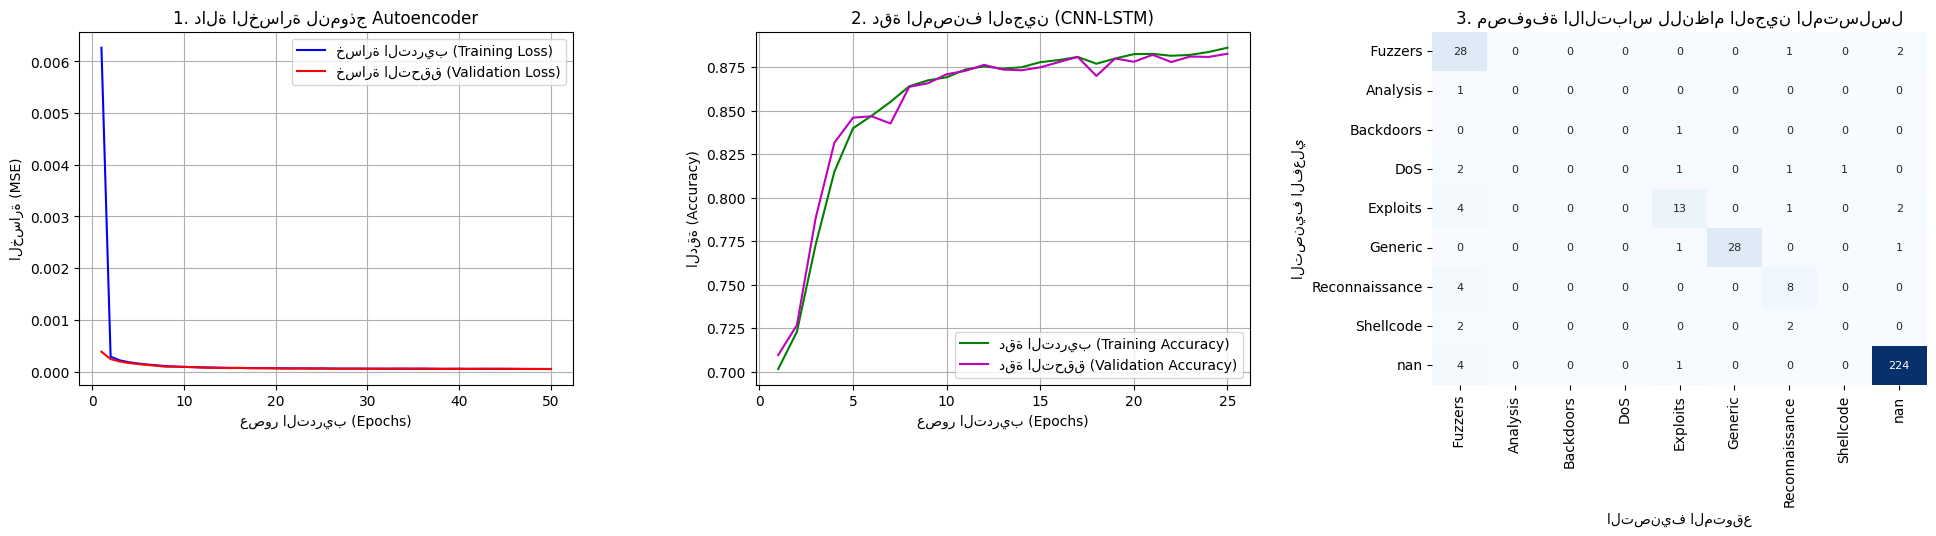

In [27]:
# 🔴 الخلية 8: عرض الرسوم البيانية لجميع النتائج (النسخة النهائية والمصححة)

import matplotlib.pyplot as plt
import seaborn as sns # ضرورية لرسم الخريطة الحرارية (Heatmap)
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix # 🛑 التأكد من استيراد هذه الدالة بشكل صحيح
import warnings
warnings.filterwarnings('ignore')


# 1. رسم بياني لأداء الـ Autoencoder (الخسارة)
if 'history_ae' in locals():
    loss_ae = history_ae.history['loss']
    val_loss_ae = history_ae.history['val_loss']
    epochs = range(1, len(loss_ae) + 1)
    
    plt.figure(figsize=(20, 6))
    plt.subplot(1, 3, 1)
    plt.plot(epochs, loss_ae, 'b', label='خسارة التدريب (Training Loss)')
    plt.plot(epochs, val_loss_ae, 'r', label='خسارة التحقق (Validation Loss)')
    plt.title('1. دالة الخسارة لنموذج Autoencoder')
    plt.xlabel('عصور التدريب (Epochs)')
    plt.ylabel('الخسارة (MSE)')
    plt.legend()
    plt.grid(True)
else:
    print("⚠️ لم يتم العثور على سجل تدريب Autoencoder (history_ae).")

# 2. رسم بياني لأداء المصنف الهجين (CNN-LSTM)
if 'history_cl' in locals():
    acc_cl = history_cl.history['accuracy']
    val_acc_cl = history_cl.history['val_accuracy']
    epochs_cl = range(1, len(acc_cl) + 1)

    if len(acc_cl) > 0:
        plt.subplot(1, 3, 2)
        plt.plot(epochs_cl, acc_cl, 'g', label='دقة التدريب (Training Accuracy)')
        plt.plot(epochs_cl, val_acc_cl, 'm', label='دقة التحقق (Validation Accuracy)')
        plt.title('2. دقة المصنف الهجين (CNN-LSTM)')
        plt.xlabel('عصور التدريب (Epochs)')
        plt.ylabel('الدقة (Accuracy)')
        plt.legend()
        plt.grid(True)
    else:
        print("⚠️ سجل تدريب المصنف الهجين (history_cl) فارغ.")
else:
    print("⚠️ لم يتم العثور على سجل تدريب المصنف الهجين (history_cl).")
    
# 3. رسم بياني لمصفوفة الالتباس (Confusion Matrix) للنظام المتسلسل
if 'y_true_final' in locals() and 'y_pred_final' in locals() and len(y_true_final) > 0:
    
    # 3.1. تجهيز مصفوفة الالتباس
    labels = np.unique(y_true_final) 
    cm = confusion_matrix(y_true_final, y_pred_final, labels=labels)
    cm_df = pd.DataFrame(cm, index=labels, columns=labels)
    
    plt.subplot(1, 3, 3)
    # استخدام seaborn لرسم الخريطة الحرارية (Heatmap)
    sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=False, annot_kws={"size": 8}) 
    plt.title('3. مصفوفة الالتباس للنظام الهجين المتسلسل')
    plt.xlabel('التصنيف المتوقع')
    plt.ylabel('التصنيف الفعلي')

    plt.tight_layout(pad=3.0)
    plt.savefig('hybrid_model_results.png')
    plt.show()

else:
    print("⚠️ لم يتم العثور على نتائج الاختبار النهائية (y_true_final و y_pred_final).")